# AE4 — Métricas, Visualizaciones e Interpretación de Negocio

**Proyecto integrador:** Patrones horarios de alquiler de bicicletas según tipo de día en Capital Bikeshare (2011–2012)  
**Equipo (Grupo 17):** Juan Esteban Casadiego Benavides y Evelyn Cerro  
**Asignatura:** Proyecto Integrador — Diseño y Documentación · Institución Universitaria Digital de Antioquia  
**Fuente de datos:** `t22000t/bike-sharing-tabular` (revisión `6b645e0cedbc5208fcca11ac94544b088478bf61`, UCI Capital Bikeshare, CC BY 4.0) preparados en `AE3/`.

## Objetivo del notebook
Construir, verificar y documentar las métricas y los gráficos que responden las tres preguntas de negocio (P1, P2 y P3) a partir de las tablas y el dataset preparado en AE3, garantizando trazabilidad exacta entre el notebook, la aplicación en Streamlit y el informe completo en PDF.

## 1. Carga de datos preparados y verificación de coherencia AE3 ↔ AE4

En primer lugar se cargan `AE3/datos/dataset_preparado.csv` y las tablas de resultados de AE3, y se ejecutan seis controles independientes que comprueban la conservación de registros, totales, ausencias y agregaciones.

In [1]:
from pathlib import Path
import sys

from IPython.display import Image, display
import pandas as pd

ruta_actual = Path.cwd().resolve()
ruta_raiz = (
    ruta_actual
    if (ruta_actual / 'AE3' / 'datos' / 'dataset_preparado.csv').exists()
    else next(
        padre
        for padre in ruta_actual.parents
        if (padre / 'AE3' / 'datos' / 'dataset_preparado.csv').exists()
    )
)
if str(ruta_raiz) not in sys.path:
    sys.path.insert(0, str(ruta_raiz))

from AE4.src.metricas_y_graficos import (
    calcular_brecha_horaria_p1,
    calcular_indicadores_generales,
    calcular_resumen_interanual_p3,
    cargar_datos_proyecto,
    exportar_resumen_ae4,
    obtener_catalogo_metricas,
    verificar_coherencia_datos,
)
from AE4.src.generar_graficos_pdf import generar_todas_las_figuras

repositorio = cargar_datos_proyecto(ruta_raiz)
comprobaciones = verificar_coherencia_datos(repositorio)
indicadores = calcular_indicadores_generales(repositorio)
assert all(item['estado'] for item in comprobaciones), 'Falló un control de coherencia'

display(pd.DataFrame(comprobaciones))
print(f"Registros observados: {indicadores['horas_observadas']:,} | Alquileres totales: {indicadores['alquileres_total']:,}")
print(f"Cobertura nominal: {indicadores['cobertura_total_pct']:.2f} % ({indicadores['horas_ausentes']} horas sin registro)")

,control,estado,detalle
0,Dimensiones del dataset preparado,True,17.379 filas × 11 columnas; 0 celdas nulas.
1,Conservación del total de alquileres,True,3.292.679 alquileres idénticos en dataset base...
2,Consistencia de cobertura y ausencias,True,165 horas sin registro en la cuadrícula nomina...
3,Recálculo independiente de P1 (hora × tipo de ...,True,48 grupos verificados (error máximo < 1e-9).
4,Recálculo independiente de P2 (franjas de seis...,True,8 grupos verificados (error máximo < 1e-9).
5,Recálculo independiente de P3 (año × hora × tipo),True,96 grupos verificados (error máximo < 1e-9).


Registros observados: 17,379 | Alquileres totales: 3,292,679
Cobertura nominal: 99.06 % (165 horas sin registro)


**Análisis de la verificación:** Los seis controles matemáticos se cumplen con error máximo inferior a `1e-9`. Los 17.379 registros horarios y 3.292.679 alquileres totales de `dataset_preparado.csv` coinciden exactamente con `p1_perfil_horario.csv`, `p2_franjas.csv`, `p3_perfil_anual.csv` y `validaciones.json`. Esta verificación asegura que ninguna cifra se introdujo manualmente.

## 2. Catálogo de métricas, fórmulas, unidades y limitaciones

A continuación se documentan todas las métricas definidas para las tres preguntas de negocio y el control transversal de cobertura, especificando su fórmula, unidad, denominador, gráfico seleccionado, decisión que podrían apoyar y sus limitaciones.

In [2]:
catalogo_metricas = obtener_catalogo_metricas()
resumen_ae4 = exportar_resumen_ae4(ruta_raiz)
rutas_figuras = generar_todas_las_figuras(ruta_raiz)
display(catalogo_metricas[['pregunta', 'metrica', 'calculo', 'unidad', 'denominador']])
print(f'Figuras regeneradas en AE4/resultados/figuras/: {len(rutas_figuras)}')

,pregunta,metrica,calculo,unidad,denominador
0,P1,Promedio de alquileres por hora registrada,Suma de alquileres_total / horas_observadas po...,Alquileres / hora registrada,Horas registradas en cada combinación hora × t...
1,P1,Mediana de alquileres por hora registrada,Percentil 50 de alquileres_total por hora y ti...,Alquileres / hora registrada,Registros horarios observados del grupo
2,P1,Brecha horaria (Laborable − No laborable),Promedio Laborable(h) − Promedio No laborable(h),Diferencia en alquileres / hora registrada,Promedios horarios por tipo de día
3,P2,Participación porcentual por franja de seis horas,(Alquileres de la franja y tipo / Total de alq...,Porcentaje (%) dentro del tipo de día,2.292.410 alquileres en Laborable; 1.000.269 e...
4,P2,Volumen acumulado e intensidad media por franja,Suma de alquileres_total y promedio por hora r...,Alquileres acumulados y alquileres / hora regi...,Horas observadas de cada franja
5,P3,Rango horario y variación interanual (2011 vs....,Rango descendente del promedio por año y tipo;...,"Posición ordinal, alquileres / hora y variació...",Promedio horario de 2011 como base comparativa
6,Calidad,Cobertura nominal de registros horarios,(horas_observadas / horas_esperadas) × 100,Porcentaje (%) y conteo de horas sin registro,Cuadrícula nominal de 17.544 horas (731 fechas...


Figuras regeneradas en AE4/resultados/figuras/: 6


**Análisis del catálogo:** Todas las métricas corresponden a **volumen operativo de alquileres registrados** (conteos físicos) o **cobertura temporal de registros**. No existen variables monetarias (tarifas, ingresos, subsidios ni costos), por lo que en ninguna pregunta se confunden alquileres con ingresos ni ingresos con rentabilidad.

## 3. P1 — Perfil horario según tipo de día

**Pregunta:** *¿Cómo varían el promedio y la mediana de alquileres por hora entre días laborables y no laborables?*

,etiqueta_hora,promedio_laborable,mediana_laborable,promedio_no_laborable,mediana_no_laborable,brecha_promedio,cobertura_laborable_pct,cobertura_no_laborable_pct
0,00:00,36.79,33.0,90.80,93.5,-54.01,99.2,99.57
1,01:00,16.55,14.0,69.51,71.0,-52.96,98.8,99.57
2,02:00,8.68,7.0,53.17,54.0,-44.49,97.4,98.70
3,03:00,4.94,4.0,25.78,25.0,-20.83,94.0,98.27
4,04:00,5.43,5.0,8.26,7.0,-2.83,94.0,98.27
5,05:00,24.91,25.0,8.69,7.0,16.22,99.0,96.10
6,06:00,102.50,104.0,18.74,16.0,83.76,99.2,99.13
7,07:00,290.61,295.0,43.41,39.0,247.21,99.2,100.00
8,08:00,477.01,463.0,105.65,94.0,371.35,99.2,100.00
9,09:00,241.52,228.0,171.62,170.0,69.89,99.2,100.00


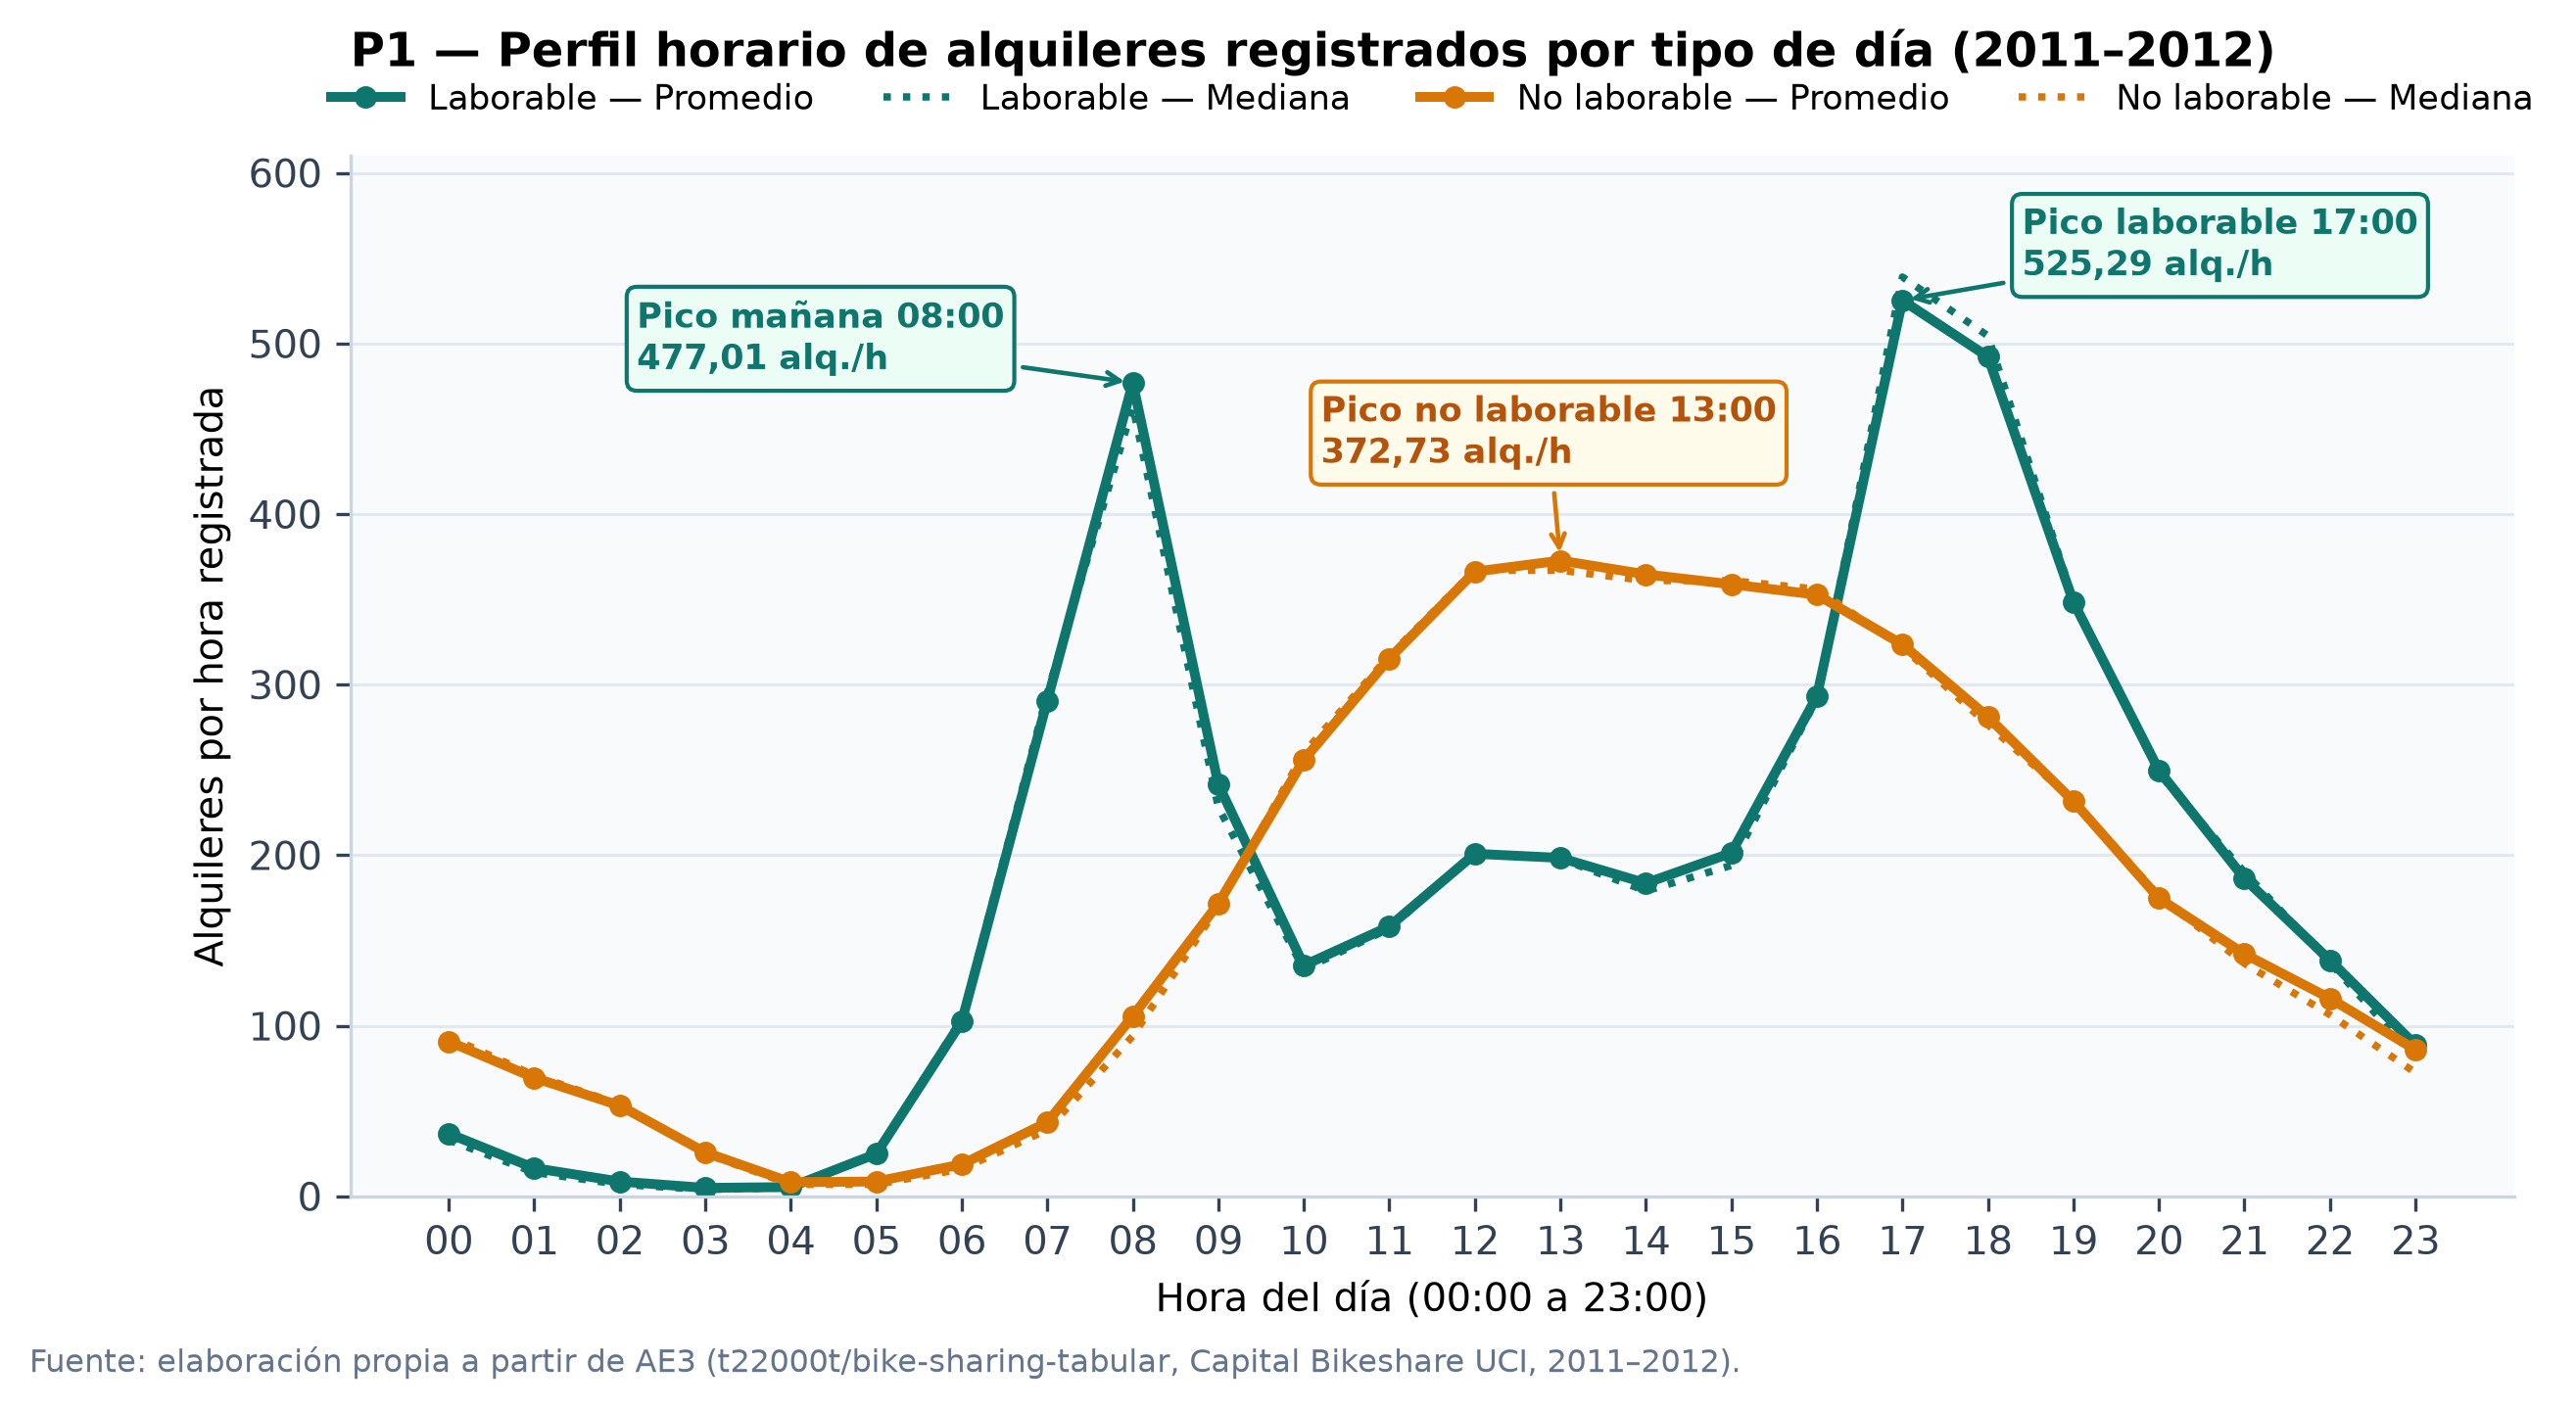

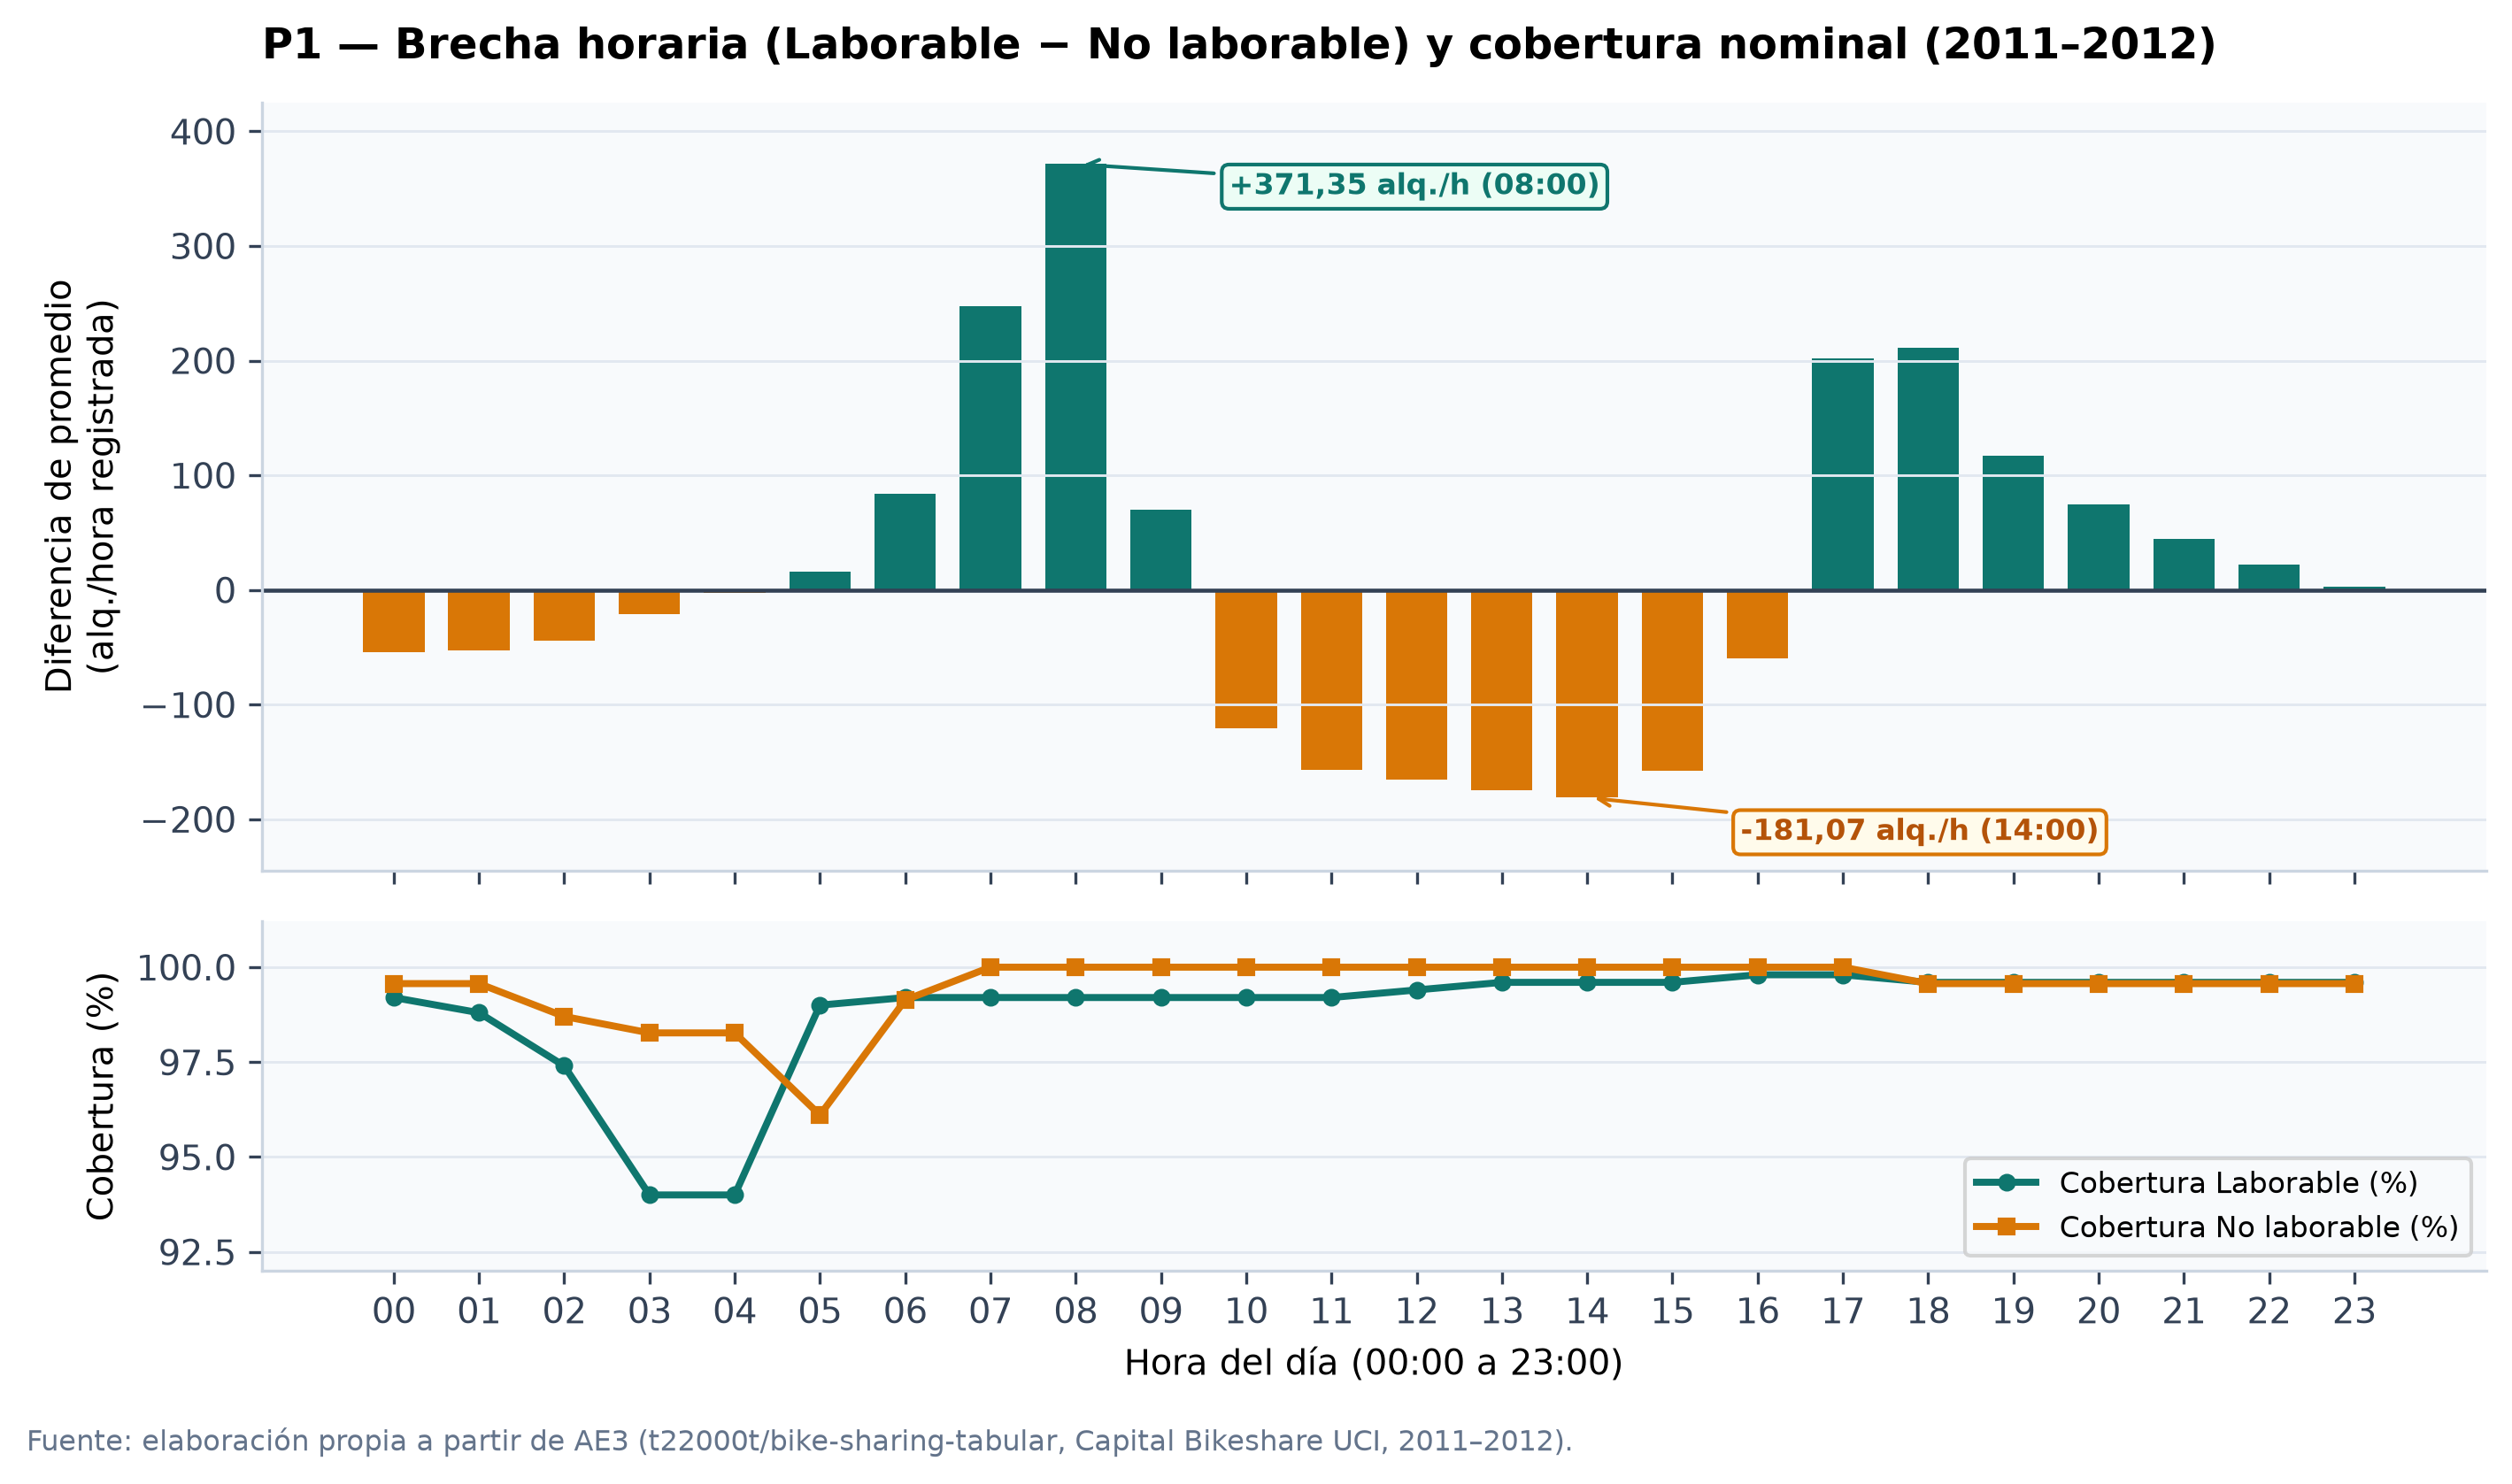

In [3]:
tabla_p1 = repositorio['tabla_p1']
tabla_brecha = calcular_brecha_horaria_p1(tabla_p1)
resumen_p1 = tabla_brecha[
    [
        'etiqueta_hora',
        'promedio_laborable',
        'mediana_laborable',
        'promedio_no_laborable',
        'mediana_no_laborable',
        'brecha_promedio',
        'cobertura_laborable_pct',
        'cobertura_no_laborable_pct',
    ]
]
display(resumen_p1.round(2))
display(Image(filename=str(ruta_raiz / 'AE4/resultados/figuras/fig01_p1_perfil_horario_media_mediana.png'), width=860))
display(Image(filename=str(ruta_raiz / 'AE4/resultados/figuras/fig02_p1_brecha_y_cobertura_horaria.png'), width=860))

**Interpretación de P1:**
- **Qué muestran los datos:** En días laborables aparece un perfil claramente **bimodal**, con picos a las **08:00** (477,01 alquileres/hora registrada, mediana 463,0) y a las **17:00** (525,29 alquileres/hora registrada, mediana 539,0; 499 observaciones, cobertura 99,80 %), seguido por las 18:00 (492,23). En días no laborables el perfil es **unimodal**, con una meseta amplia entre las 12:00 y las 16:00 y máximo a las **13:00** (372,73 alquileres/hora registrada, mediana 367,0; 231 observaciones, cobertura 100,00 %). La mayor ventaja laborable se da a las 08:00 (+371,35 alq./h) y la mayor ventaja no laborable a las 14:00 (−181,07 alq./h).
- **Decisión operativa apoyada:** En el escenario hipotético, permite diseñar esquemas de seguimiento y revisión diferenciados por calendario (ventanas 07:00–09:00 y 17:00–19:00 en laborables; bloque continuo 11:00–17:00 en fines de semana y festivos).
- **Limitaciones:** Describe alquileres efectivamente concretados (no demanda insatisfecha ni escasez de bicicletas), no demuestra causalidad laboral y no equivale a ingresos ni rentabilidad. Las horas 03:00 y 04:00 en laborables presentan 30 ausencias cada una (cobertura 94,00 %).

## 4. P2 — Distribución por franjas de seis horas

**Pregunta:** *¿Qué franjas de seis horas concentran más alquileres dentro de cada tipo de día?*

,tipo_dia,franja_horaria,horas_observadas,alquileres_total,promedio_alquileres_por_hora,mediana_alquileres_por_hora,participacion_alquileres_pct,cobertura_pct
0,Laborable,00 a 05,2912,47859,16.44,10.0,2.09,97.07
1,Laborable,06 a 11,2976,696996,234.21,187.0,30.40,99.20
2,Laborable,12 a 17,2989,798696,267.21,226.0,34.84,99.63
3,Laborable,18 a 23,2988,748859,250.62,197.0,32.67,99.60
4,No laborable,00 a 05,1364,58650,43.00,27.0,5.86,98.41
5,No laborable,06 a 11,1384,210323,151.97,99.5,21.03,99.86
6,No laborable,12 a 17,1386,494046,356.45,358.0,49.39,100.00
7,No laborable,18 a 23,1380,237250,171.92,144.0,23.72,99.57


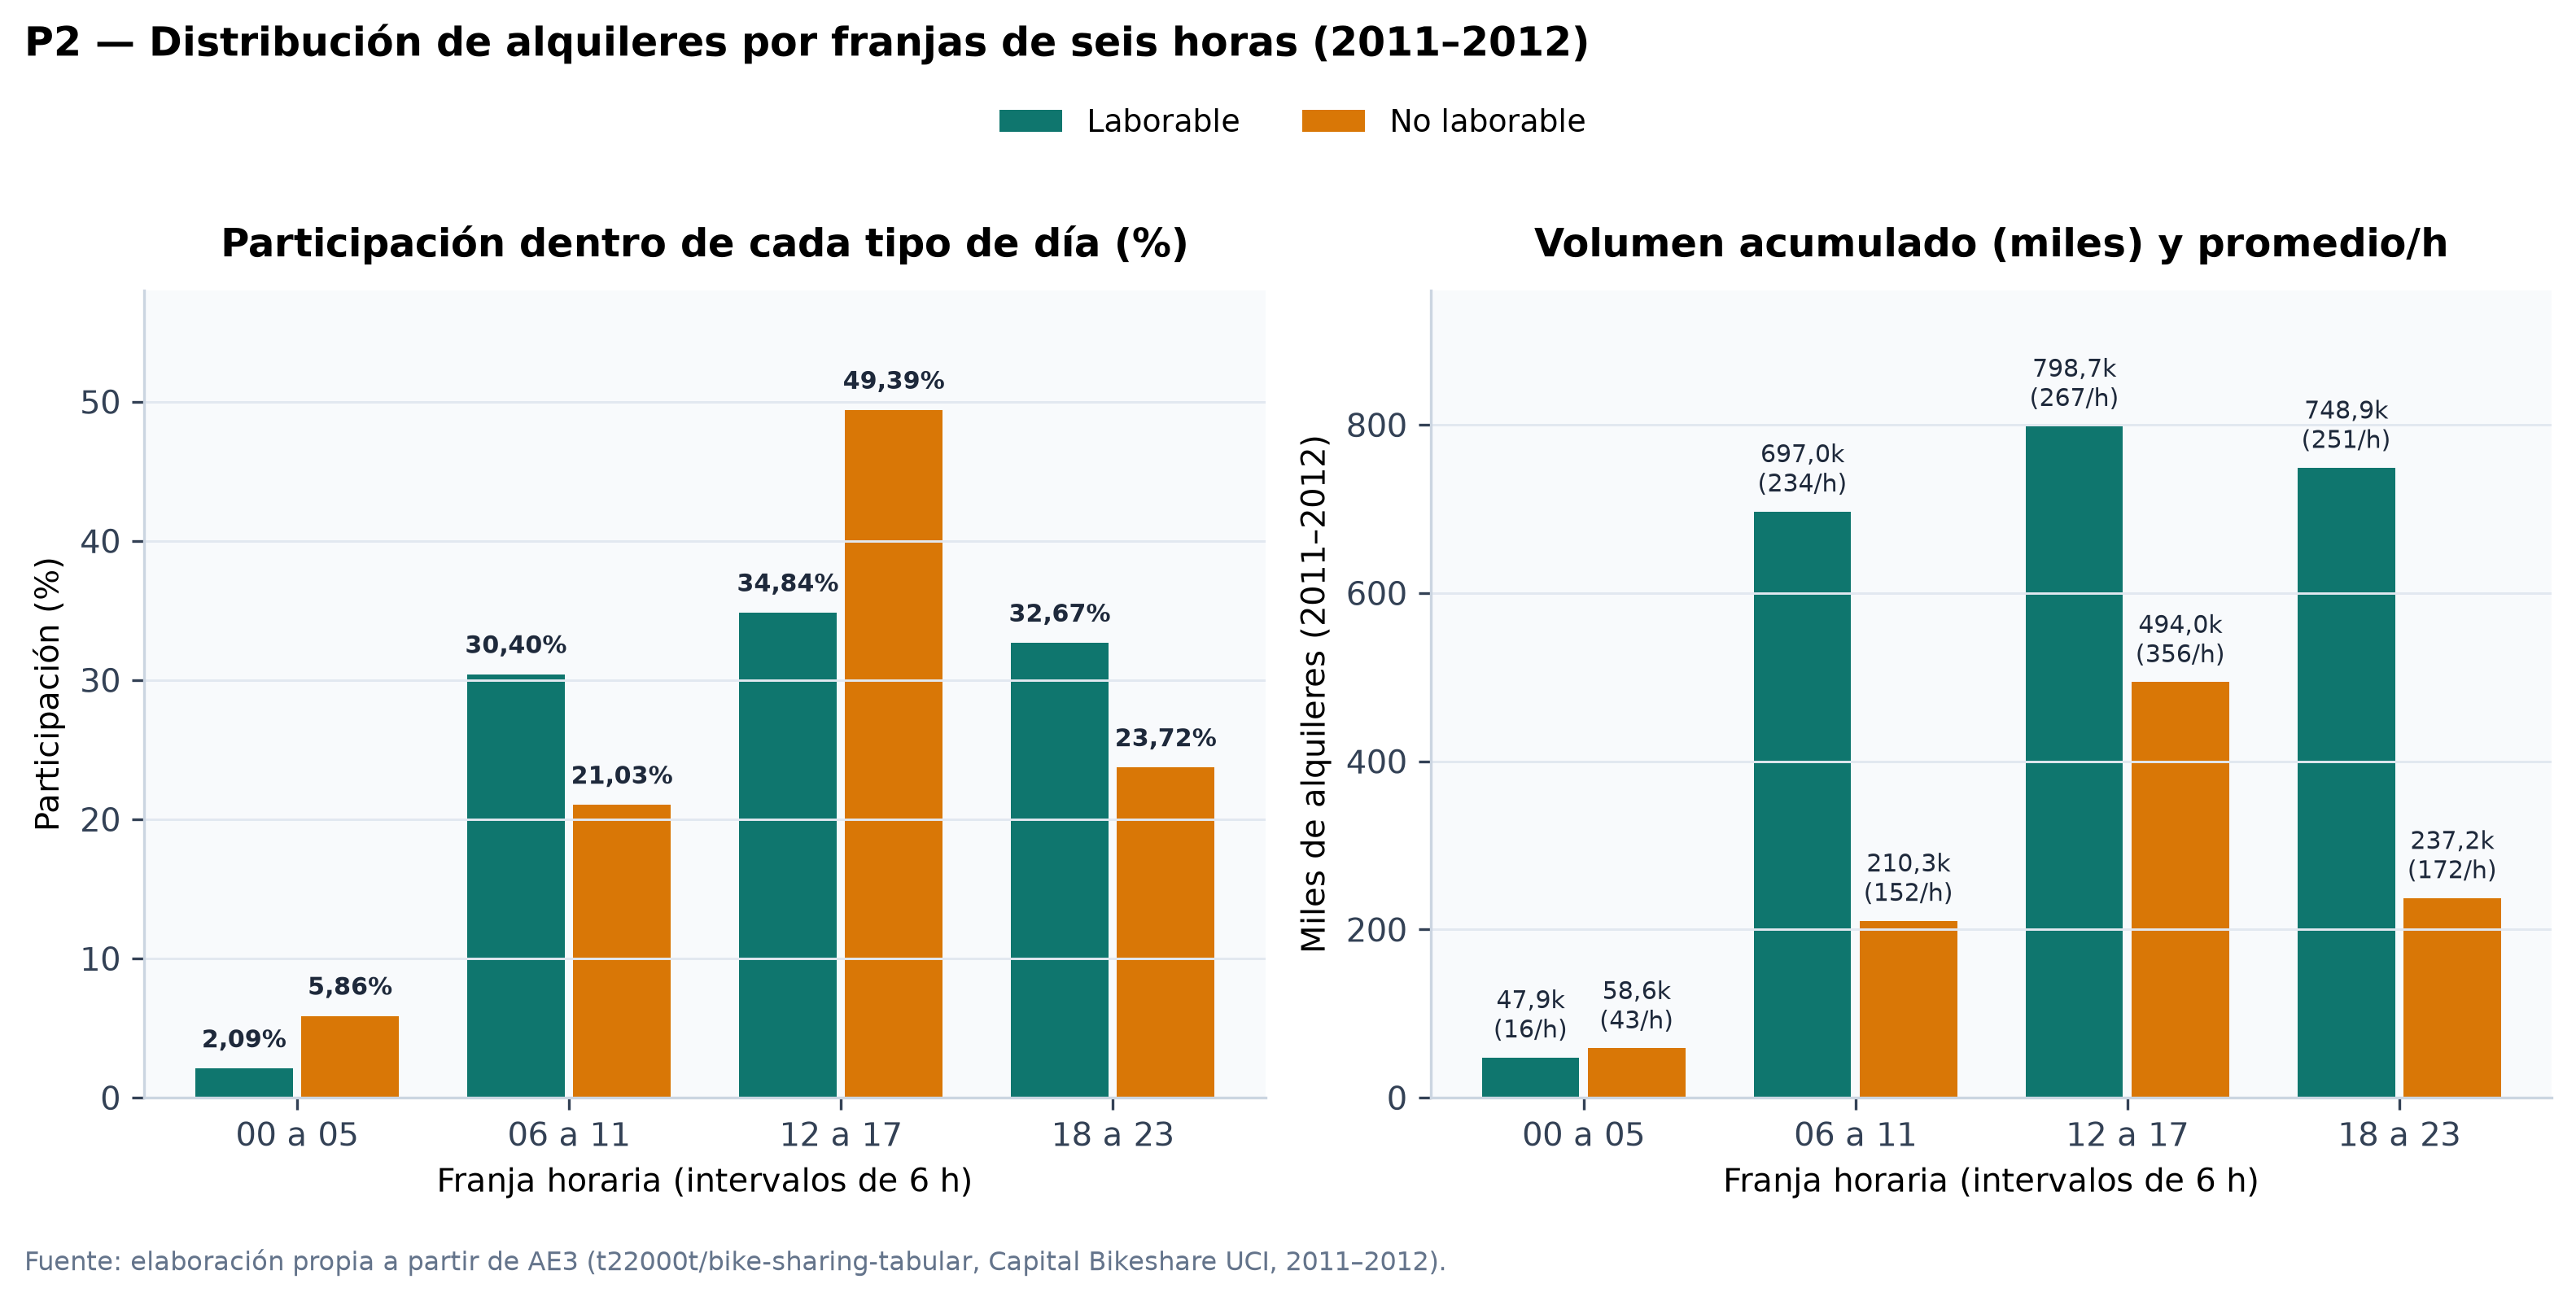

In [4]:
tabla_p2 = repositorio['tabla_p2']
display(
    tabla_p2[
        [
            'tipo_dia',
            'franja_horaria',
            'horas_observadas',
            'alquileres_total',
            'promedio_alquileres_por_hora',
            'mediana_alquileres_por_hora',
            'participacion_alquileres_pct',
            'cobertura_pct',
        ]
    ].round(2)
)
display(Image(filename=str(ruta_raiz / 'AE4/resultados/figuras/fig03_p2_participacion_y_volumen_franjas.png'), width=880))

**Interpretación de P2:**
- **Qué muestran los datos:** La franja **12 a 17** concentra la mayor participación dentro de ambos tipos de día: **34,84 %** en laborables (798.696 alquileres sobre 2.292.410) y **49,39 %** en no laborables (494.046 alquileres sobre 1.000.269). En días laborables el uso se reparte de manera más equilibrada entre tres franjas (`06 a 11`: 30,40 %, `12 a 17`: 34,84 %, `18 a 23`: 32,67 %), mientras que en no laborables casi la mitad ocurre en `12 a 17`. Además, aunque el volumen total de `12 a 17` es mayor en laborables (por contar con 500 días frente a 231), la intensidad media por hora es **mayor en no laborables** (**356,45** vs. **267,21** alq./h).
- **Decisión operativa apoyada:** Ayuda a organizar la supervisión por bloques de seis horas, manteniendo atención continua entre las 06:00 y las 23:00 en laborables y priorizando el bloque 12:00–17:00 en fines de semana y festivos.
- **Limitaciones:** Las franjas son cortes nominales del proyecto (`hora // 6`), no turnos oficiales; agrupan horas con distinta intensidad (como las 14:00 y las 17:00 en laborables) y no representan ingresos ni rentabilidad.

## 5. P3 — Estabilidad de horarios máximos entre 2011 y 2012

**Pregunta:** *¿Se mantienen los horarios de mayor promedio al separar 2011 y 2012 para cada tipo de día?*

,anio,tipo_dia,hora,horas_observadas,promedio_alquileres_por_hora,mediana_alquileres_por_hora,cobertura_pct
0,2011,Laborable,17,250,394.92,430.0,100.0
1,2012,Laborable,17,249,656.19,704.0,99.6
2,2011,No laborable,13,115,285.80,314.0,100.0
3,2012,No laborable,13,116,458.91,492.5,100.0


,tipo_dia,hora_pico_2011,hora_pico_2012,coincide_hora_pico,promedio_pico_2011,promedio_pico_2012,cambio_pico_pct,total_anual_2011,total_anual_2012,cambio_total_anual_pct
0,Laborable,17,17,True,394.92,656.19,66.16,856264,1436146,67.72
1,No laborable,13,13,True,285.80,458.91,60.57,386839,613430,58.58


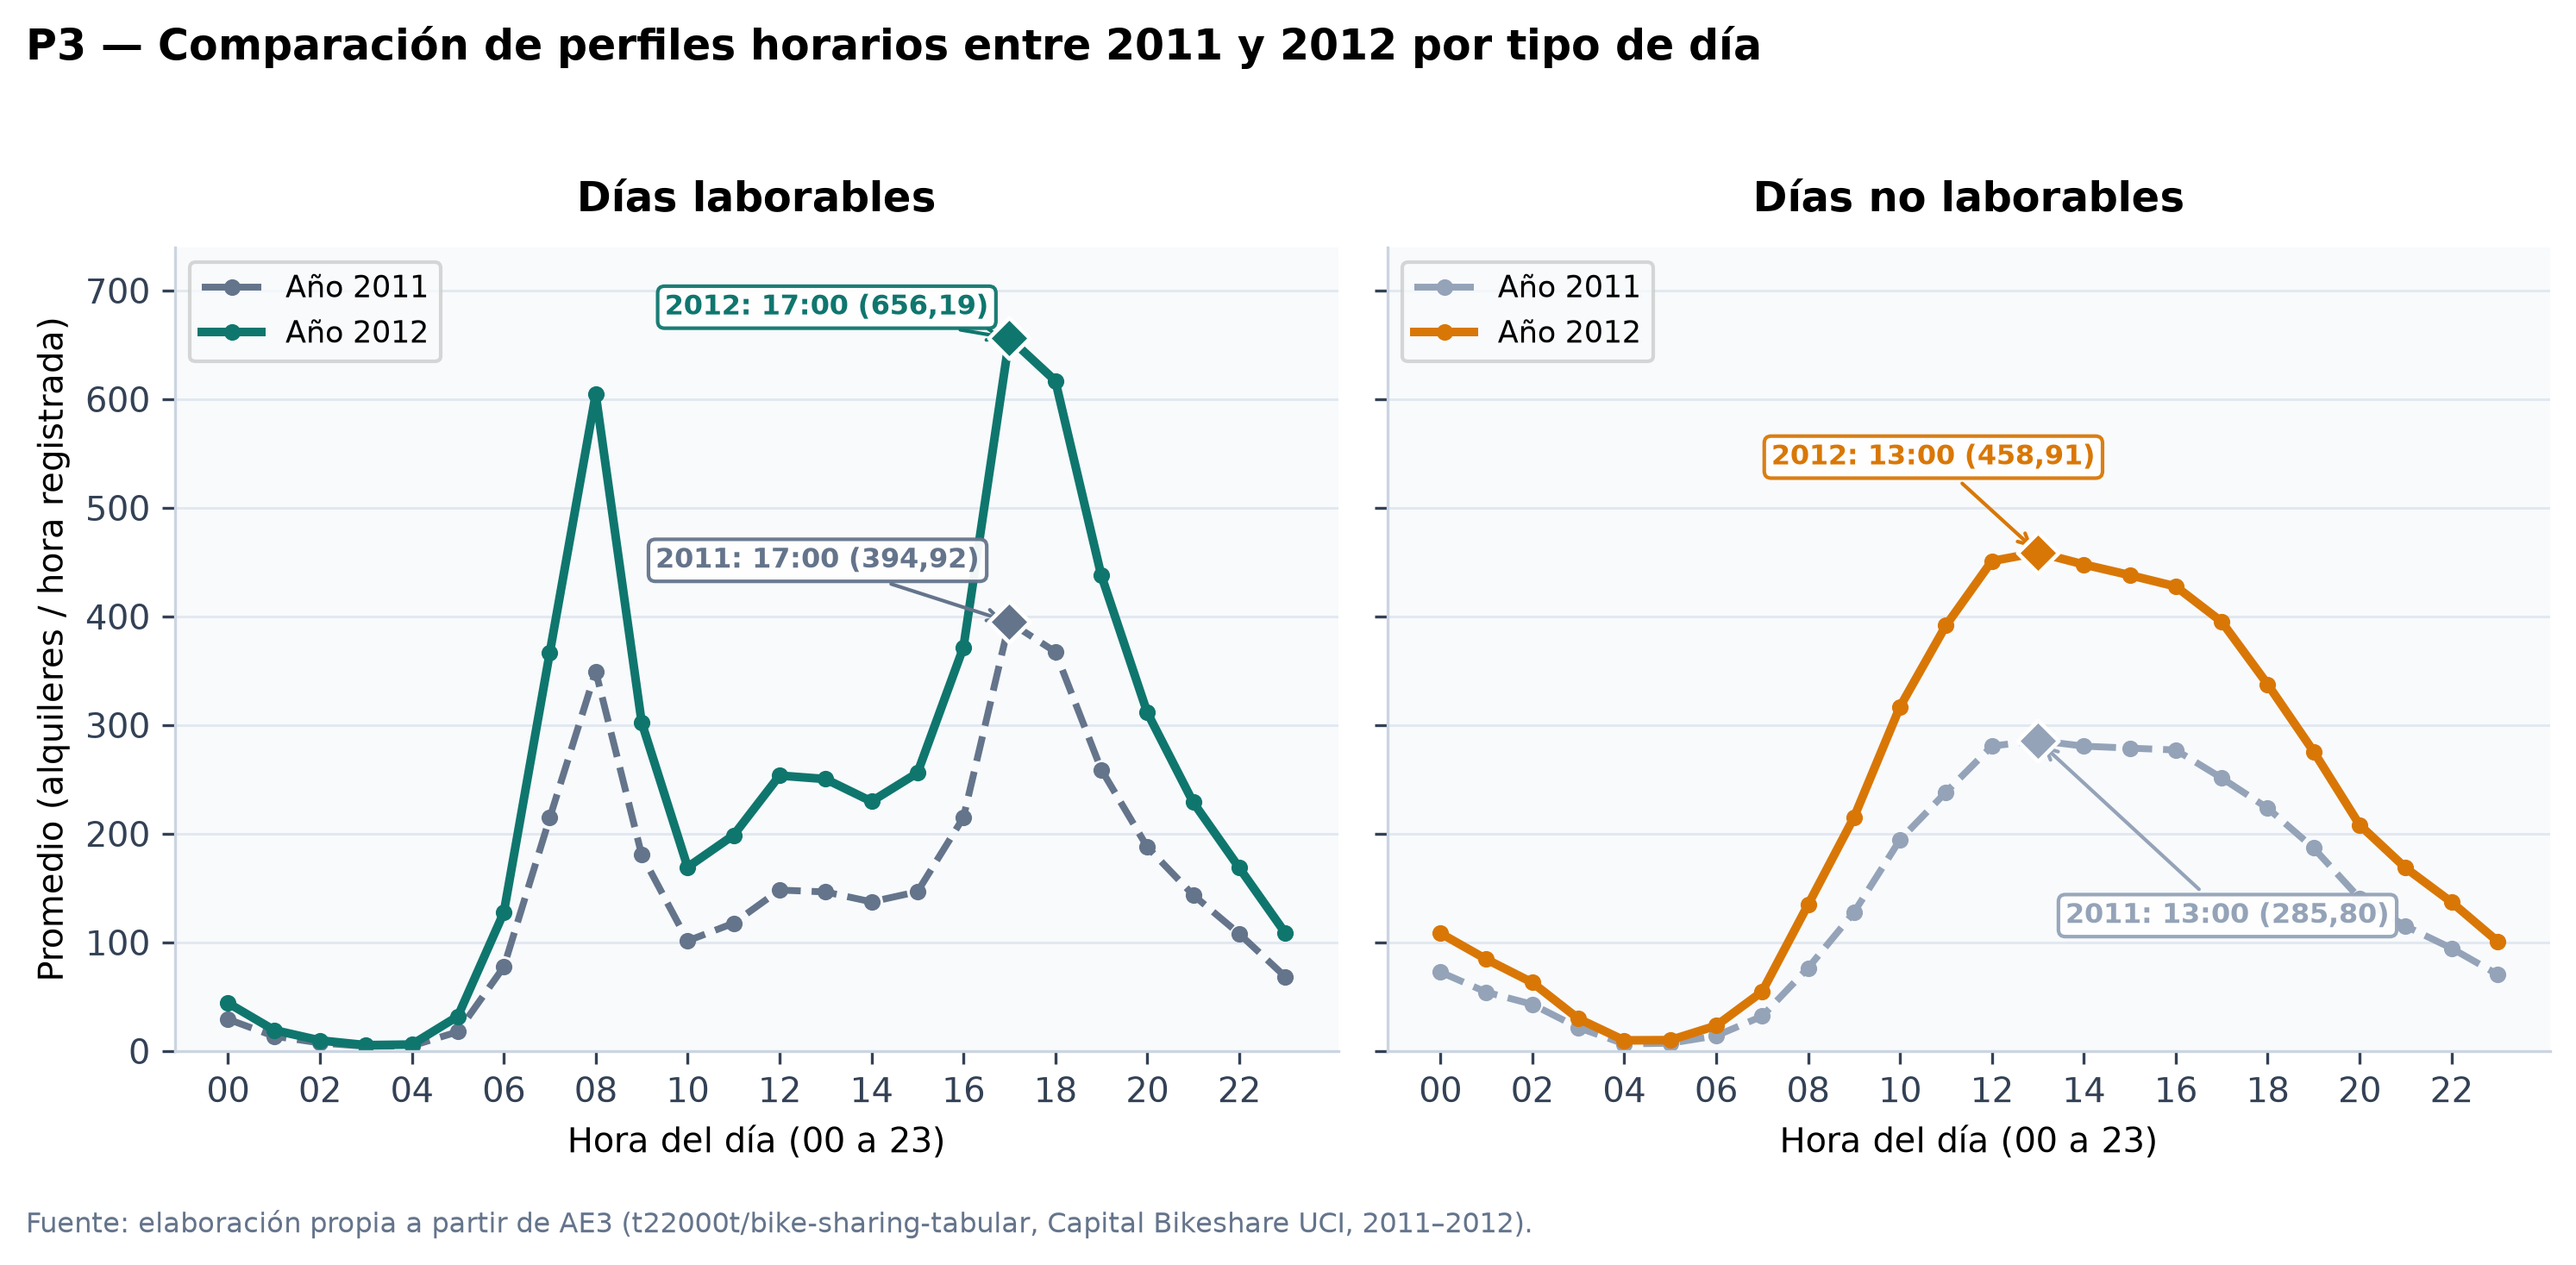

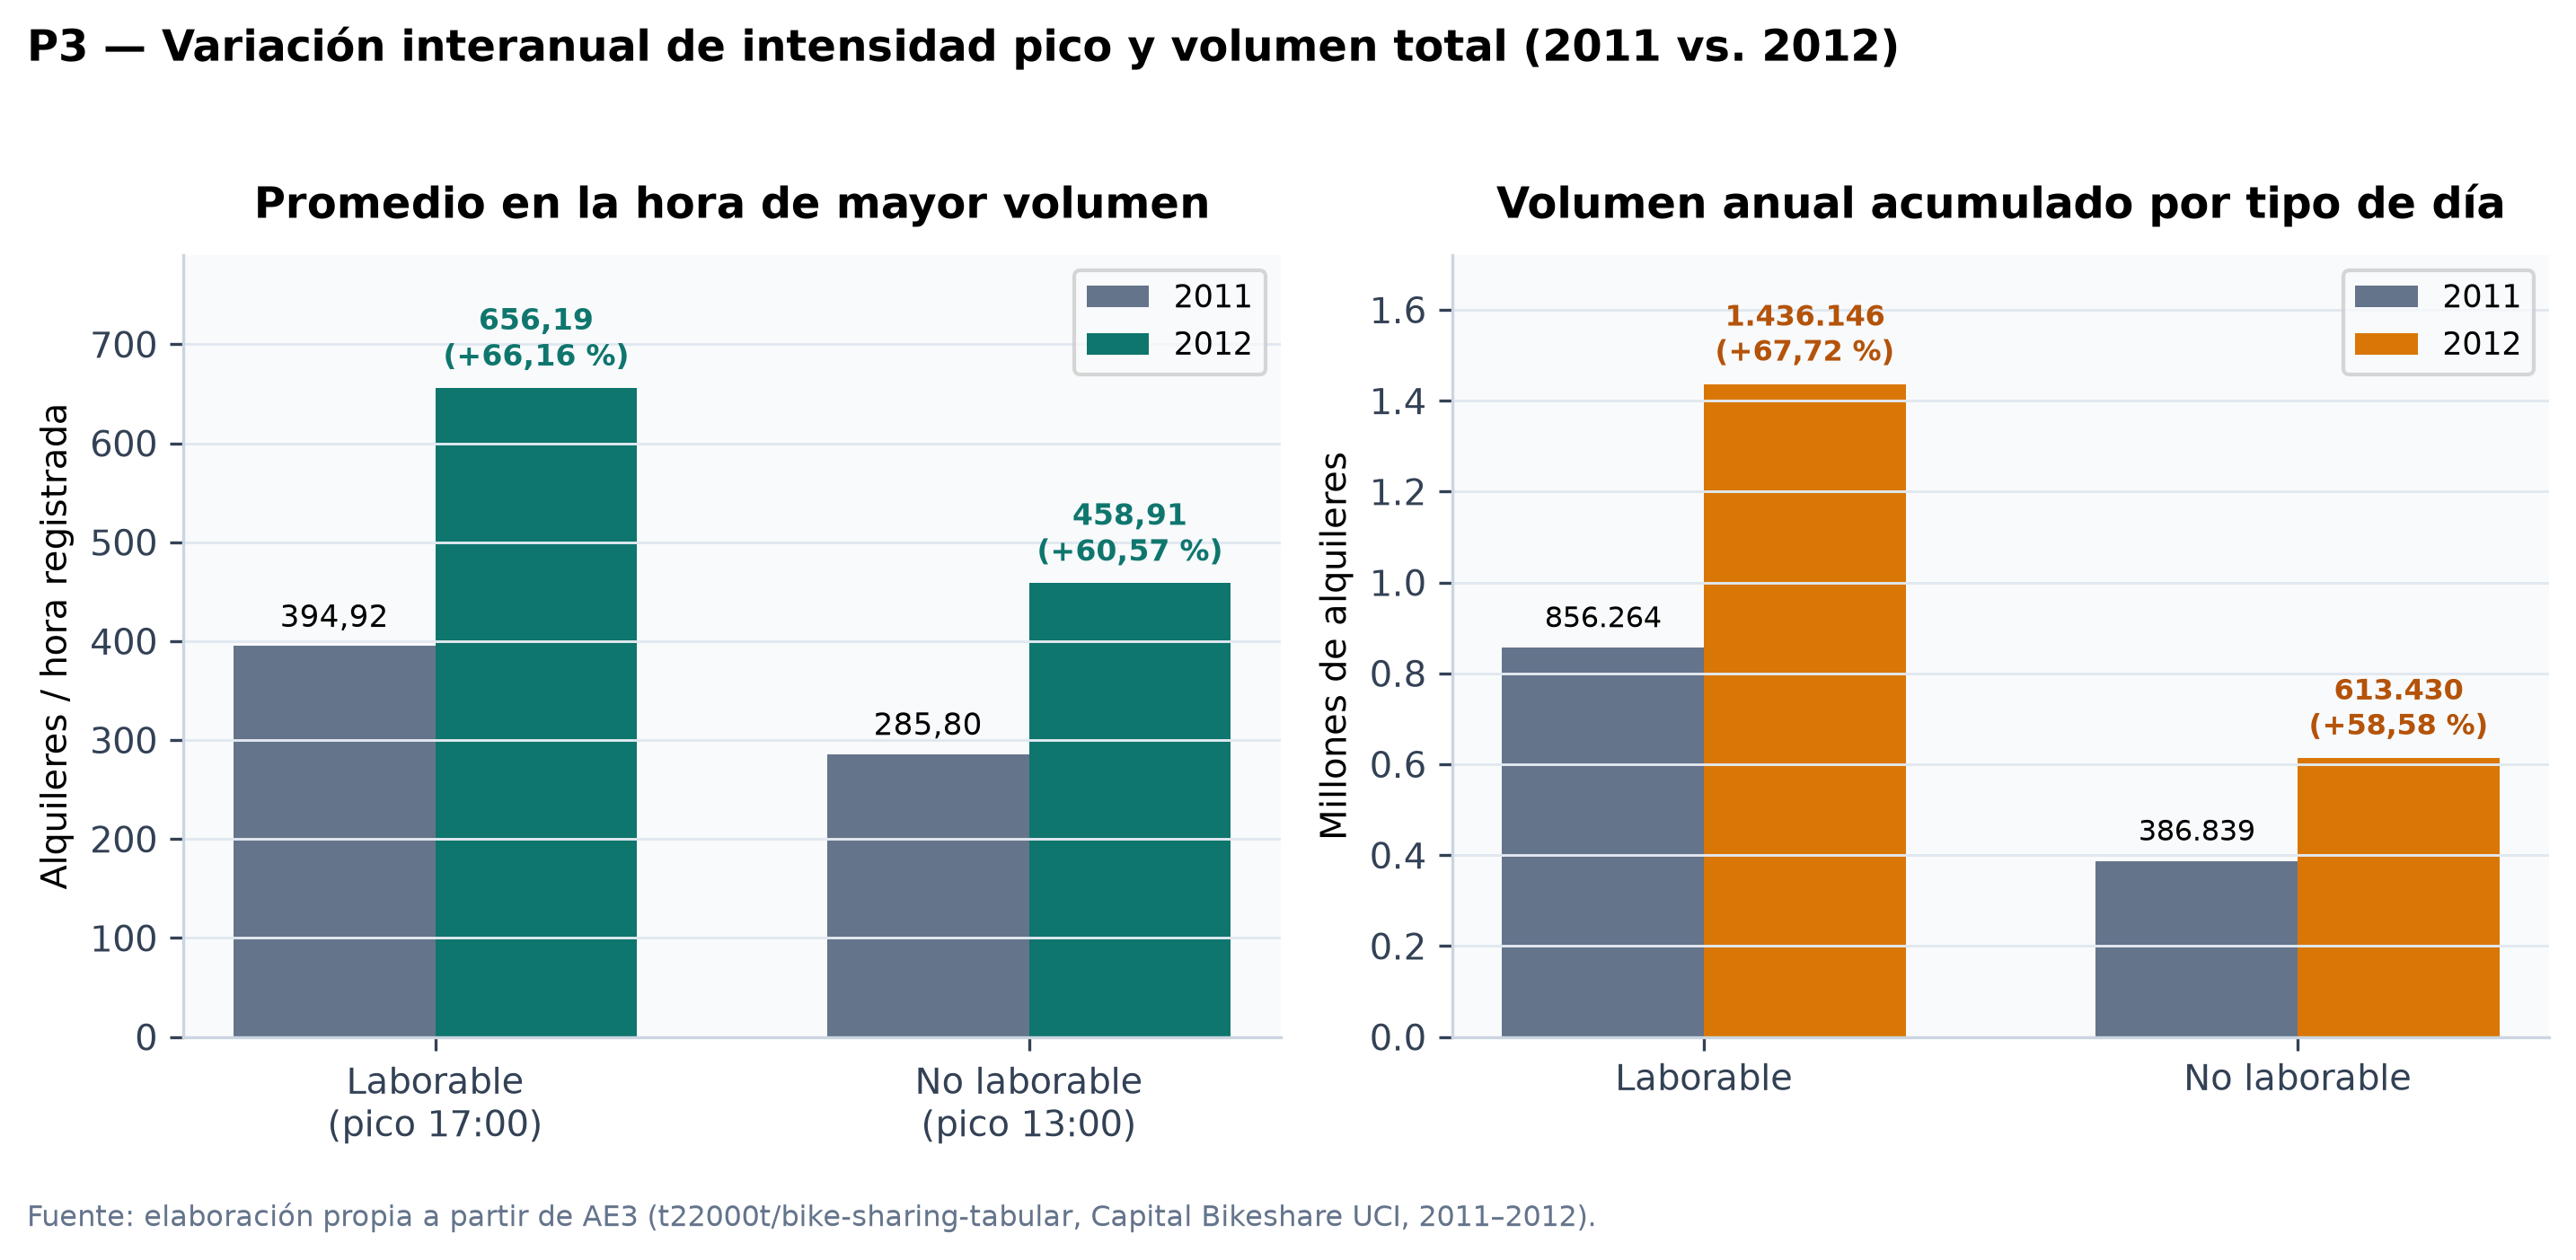

In [5]:
tabla_p3 = repositorio['tabla_p3']
picos_anuales, comparacion_anual = calcular_resumen_interanual_p3(tabla_p3)
display(
    picos_anuales[
        [
            'anio',
            'tipo_dia',
            'hora',
            'horas_observadas',
            'promedio_alquileres_por_hora',
            'mediana_alquileres_por_hora',
            'cobertura_pct',
        ]
    ].round(2)
)
display(
    comparacion_anual[
        [
            'tipo_dia',
            'hora_pico_2011',
            'hora_pico_2012',
            'coincide_hora_pico',
            'promedio_pico_2011',
            'promedio_pico_2012',
            'cambio_pico_pct',
            'total_anual_2011',
            'total_anual_2012',
            'cambio_total_anual_pct',
        ]
    ].round(2)
)
display(Image(filename=str(ruta_raiz / 'AE4/resultados/figuras/fig04_p3_comparacion_anual_perfiles.png'), width=880))
display(Image(filename=str(ruta_raiz / 'AE4/resultados/figuras/fig05_p3_variacion_interanual_maximos.png'), width=880))

**Interpretación de P3:**
- **Qué muestran los datos:** Las horas de mayor promedio **sí se mantienen** al separar los años: **17:00** en días laborables y **13:00** en días no laborables tanto en 2011 como en 2012. Sin embargo, el nivel crece de forma marcada: en laborables el pico de las 17:00 pasa de **394,92** a **656,19** alq./h (**+66,16 %**) y en no laborables el pico de las 13:00 pasa de **285,80** a **458,91** alq./h (**+60,57 %**). El volumen anual total aumenta de **1.243.103** alquileres en 2011 a **2.049.576** en 2012 (**+64,88 %**).
- **Decisión operativa apoyada:** Confirma que las franjas horarias pico son referencias estables para la planeación operativa, pero muestra que la magnitud de carga debe revisarse periódicamente porque el volumen puede escalar rápidamente entre años.
- **Limitaciones:** Comparar dos años históricos no demuestra una tendencia futura ni explica las causas del incremento (como ampliación de flota, estaciones, clima o adopción). Tampoco demuestra un incremento proporcional en ingresos o rentabilidad.

## 6. Transparencia de cobertura: las 165 horas sin registro

,anio,tipo_dia,horas_esperadas,horas_observadas,horas_sin_registro,cobertura_pct
0,2011,Laborable,6000,5911,89,98.52
1,2011,No laborable,2760,2734,26,99.06
2,2012,Laborable,6000,5954,46,99.23
3,2012,No laborable,2784,2780,4,99.86


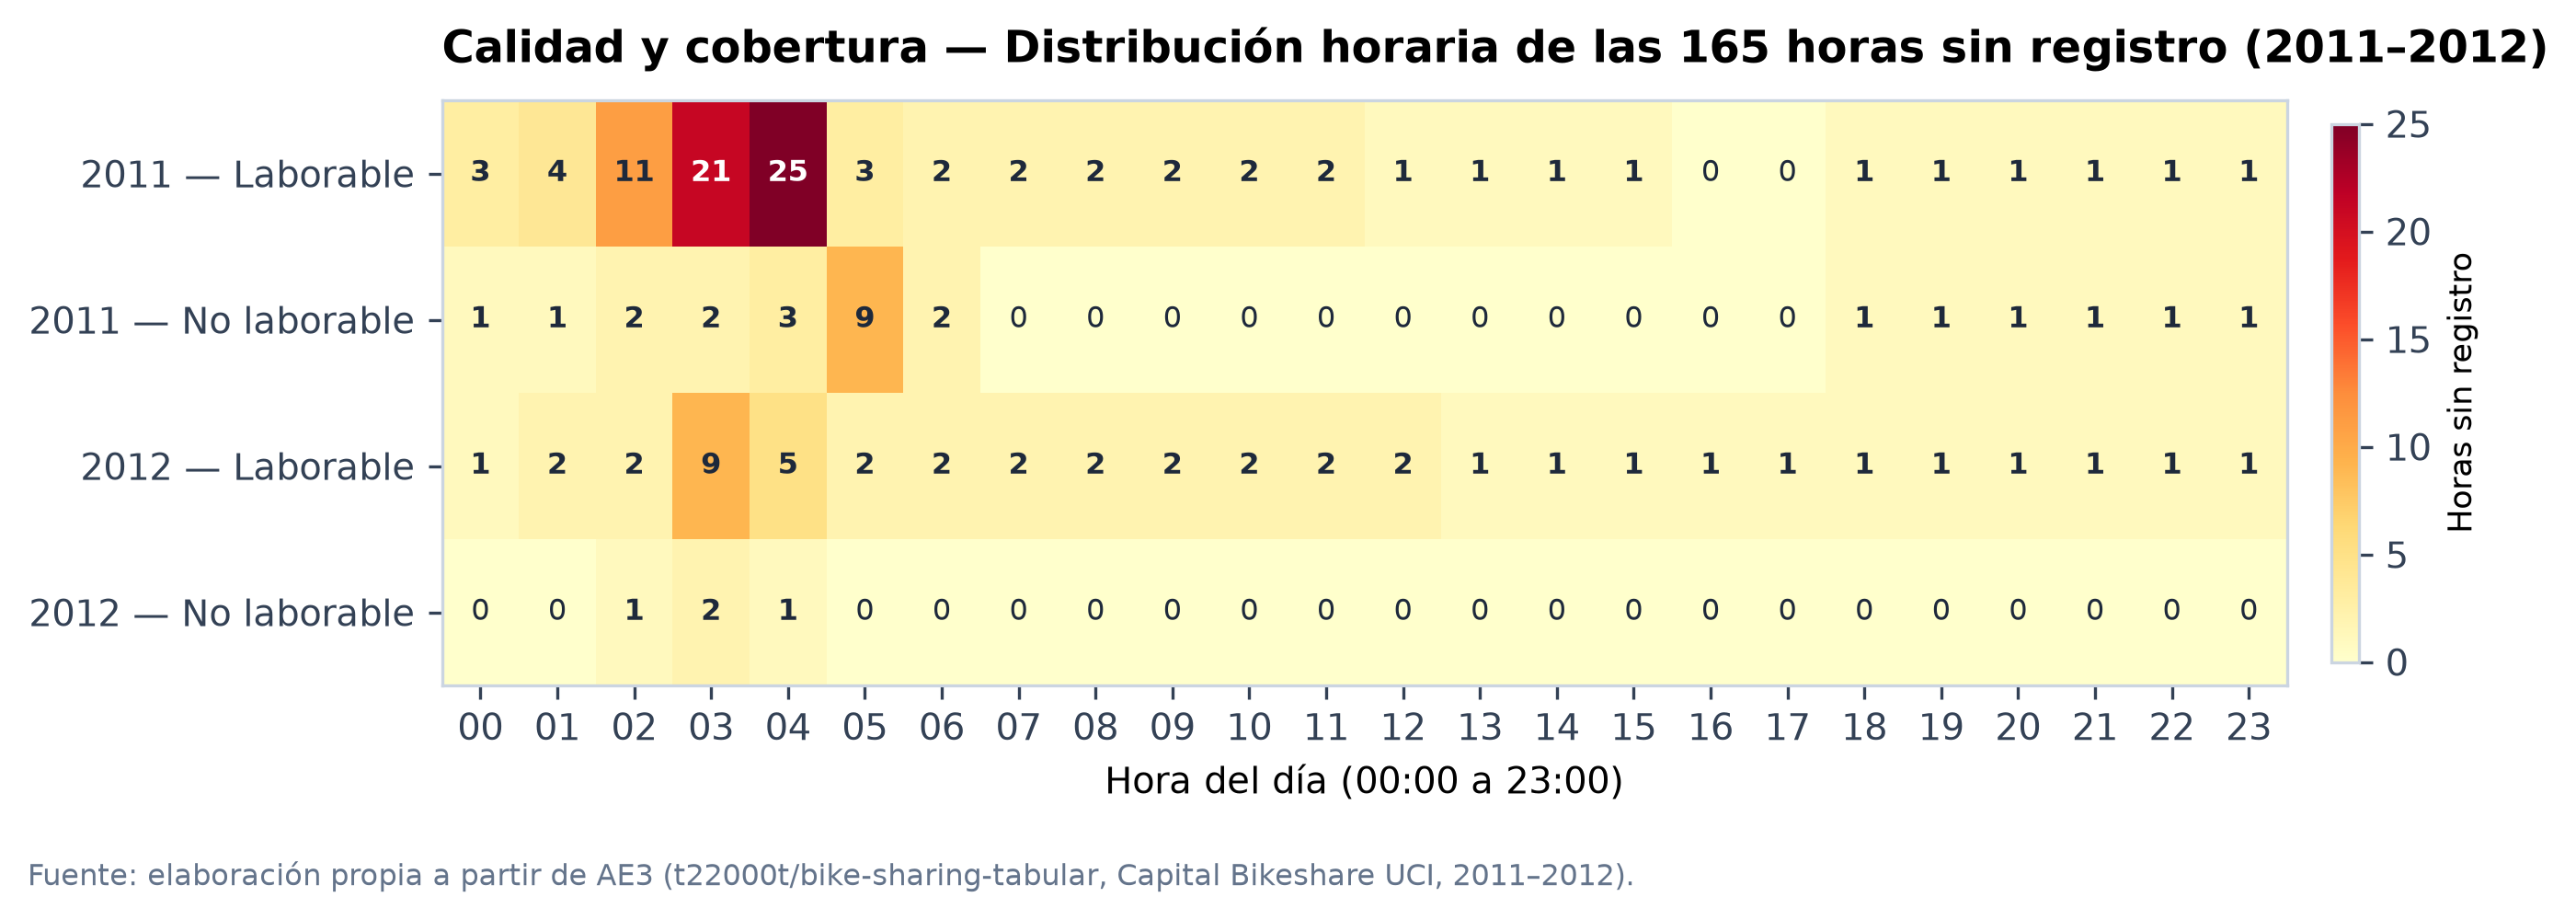

In [6]:
display(repositorio['cobertura_anual'].round(2))
display(Image(filename=str(ruta_raiz / 'AE4/resultados/figuras/fig06_cobertura_calidad_registros.png'), width=880))

**Análisis de cobertura:** Sobre una cuadrícula nominal de 17.544 combinaciones fecha-hora (731 fechas × 24 horas), se observan 17.379 registros (99,06 %) y faltan 165 horas, concentradas principalmente en 2011 (115 de 165) y en la madrugada (02:00 a 05:00). Estas ausencias no se imputan como cero alquileres y se reportan explícitamente como límite metodológico.

## Resumen final de resultados AE4

### Preguntas y respuestas
- **P1 (Perfil horario):** Los días laborables siguen una distribución bimodal con picos a las 08:00 (477,01 alq./h; mediana 463,0) y 17:00 (525,29 alq./h; mediana 539,0; cobertura 99,80 %). Los días no laborables muestran una curva unimodal con máximo a las 13:00 (372,73 alq./h; mediana 367,0; cobertura 100,00 %).
- **P2 (Franjas de seis horas):** La franja 12 a 17 concentra el mayor porcentaje dentro de cada tipo de día: 34,84 % en laborables (798.696 alquileres; 267,21 alq./h) y 49,39 % en no laborables (494.046 alquileres; 356,45 alq./h).
- **P3 (Consistencia 2011 vs. 2012):** Sí, las horas de mayor promedio se mantienen en 17:00 (laborable) y 13:00 (no laborable) en ambos años, mientras sus promedios crecen +66,16 % (de 394,92 a 656,19) y +60,57 % (de 285,80 a 458,91), respectivamente.

### Hallazgos clave del análisis
- Se verificó coincidencia exacta (error < 1e-9) en los 17.379 registros y 3.292.679 alquileres totales entre el dataset preparado, las tablas AE3, este notebook y la aplicación de Streamlit.
- La brecha horaria Laborable − No laborable alcanza +371,35 alq./h a las 08:00 y +201,74 alq./h a las 17:00, mientras que entre 10:00 y 16:00 predominan los días no laborables (brecha máxima de −181,07 alq./h a las 14:00).
- Aunque los días laborables acumulan mayor volumen absoluto en la franja 12 a 17 por tener 500 días frente a 231 no laborables, la intensidad media horaria de esa franja es superior en días no laborables (356,45 vs. 267,21 alq./h).

### Conclusiones, limitaciones y próximos pasos
- **Volumen frente a ingresos y rentabilidad:** Los datos miden únicamente alquileres registrados (volumen físico). No permiten estimar ingresos ni rentabilidad porque carecen de estructura tarifaria, membresías y costos operativos (mantenimiento, redistribución y personal).
- **Próximos pasos para decisiones operativas reales:** Incorporar registros por estación (para medir escasez o saturación de anclajes), información económica de tarifas y costos, y mediciones actuales de la ciudad objetivo tras auditar variables climáticas.